In [35]:
!pip install numpy matplotlib yfinance scipy

import numpy as np
import yfinance
import pandas as pd
from matplotlib import pyplot as plt

In [20]:
data = yfinance.download("AMZN", start="2025-01-01", end="2026-01-01")
close = data["Close"]

[*********************100%***********************]  1 of 1 completed


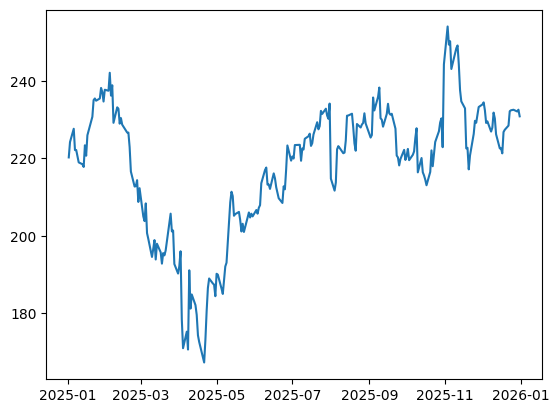

In [3]:
plt.plot(close)

[0.0001888] [0.0216269]


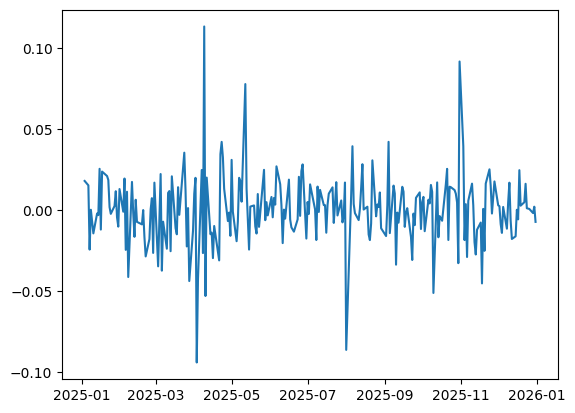

In [4]:
log_returns = np.log(close/close.shift(1)).iloc[1:]
mu = log_returns.mean().values
sigma = log_returns.std().values

print(mu, sigma)

plt.plot(log_returns)

In [5]:
T = 252
N = 1000
r = 0.05/T # 5% annually

K = 230

In [6]:
def MC_simulation(T, N, mu, sigma, close):
    dt = 1
    Z = np.random.standard_normal(size=(T, N))
    returns = np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
    
    S0 = close.iloc[-1].values[0]
    paths = S0*np.cumprod(returns, axis=0)

    return paths

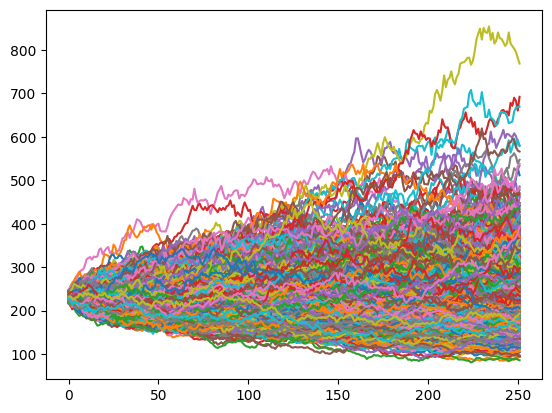

In [7]:
paths = MC_simulation(T, N, r, sigma, close) 

plt.plot(paths)
plt.show()

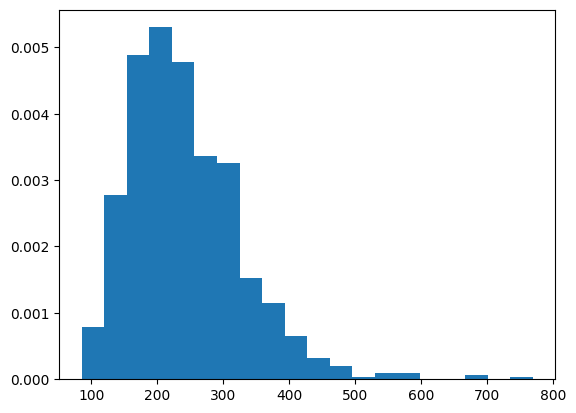

In [8]:
"""
X = paths[-1, :]


sigma = X.std()

x = np.linspace(X.min(), X.max(), 500)

pdf = 1 / np.sqrt(2*np.pi*sigma**2) * np.exp(
    -0.5 * (x-mu)**2 / sigma**2
)
"""
plt.hist(paths[-1, :], density=True, bins=20)
#plt.plot(x, pdf, c="orange", lw=2)
plt.show()

## European Option Pricing with Black-Scholes

In [16]:
def monte_carlo_pricing(S0, N, r, sigma, T, K, close):
    Z = np.random.standard_normal(N)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    
    payoff = np.maximum(ST - K, 0)
    price = np.exp(-r*T) * np.mean(payoff)

    return price, payoff

38.26573789507894


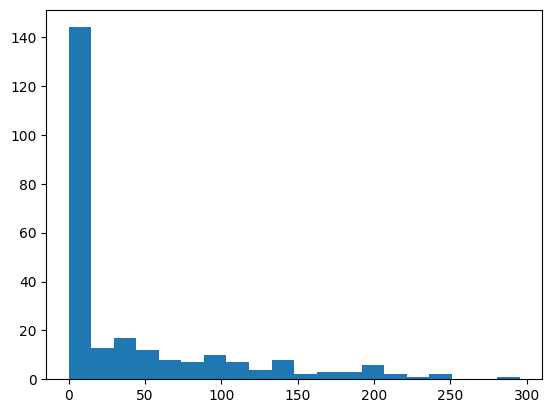

In [24]:
S0 = close.iloc[-1].values[0]
price, payoff = monte_carlo_pricing(S0, N, r, sigma, T, K, close)

print(price)
plt.hist(payoff, bins=20)
plt.show()

In [18]:
# We implement black scholes formula for european option to compare the value with the mc method
from scipy.stats import norm

def bs_european_call(S0, K, r, T, sigma):
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    
    C = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    return C

bs_price = bs_european_call(S0, K, r, T, sigma)[0]
print(f"Call option price by Black-Scholes formula: {round(bs_price, 4)}")

Call option price by Black-Scholes formula: 37.026


In [32]:
Nvalues = [250, 1000, 10_000, 100_000, 1_000_000]

for N in Nvalues:
    price, payoff = monte_carlo_pricing(S0, N, r, sigma, T, K, close)
    print(f"Iterations: {N:<7} | MC price: {round(price, 4):<7} | Error {round(price-bs_price, 4):<7} | Error (%): {abs(round((price-bs_price)/bs_price, 3))}")

Iterations: 250     | MC price: 42.2998 | Error 5.2739  | Error (%): 0.142
Iterations: 1000    | MC price: 38.9921 | Error 1.9661  | Error (%): 0.053
Iterations: 10000   | MC price: 37.3871 | Error 0.3612  | Error (%): 0.01
Iterations: 100000  | MC price: 37.1486 | Error 0.1226  | Error (%): 0.003
Iterations: 1000000 | MC price: 36.9528 | Error -0.0731 | Error (%): 0.002


## Volatility Smile

In [36]:
ticker = yfinance.Ticker("AMZN")
expiry = ticker.options[2]
calls = ticker.option_chain(expiry).calls.copy()

S0 = float(ticker.history(period="1d")["Close"].iloc[-1])
calls["mid"] = (calls["ask"] + calls["bid"]) / 2
T = (pd.Timestamp(expiry).date() - pd.Timestamp.now().date()).days / 365
r = 0.0439

calls

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,mid
0,AMZN261111C00190000,2026-10-30 15:22:58+00:00,190.0,51.59,69.20,72.00,0.000000,0.000000,2.0,1,1.187504,True,REGULAR,USD,70.600
1,AMZN261111C00197500,2026-10-30 14:19:10+00:00,197.5,39.05,61.75,64.30,0.000000,0.000000,4.0,2,1.023442,True,REGULAR,USD,63.025
2,AMZN261111C00200000,2026-10-30 13:41:17+00:00,200.0,37.75,59.25,61.80,0.000000,0.000000,3.0,5,0.983399,True,REGULAR,USD,60.525
3,AMZN261111C00205000,2026-10-29 15:30:07+00:00,205.0,44.30,54.30,56.80,0.000000,0.000000,NaN,15,0.916016,True,REGULAR,USD,55.550
4,AMZN261111C00215000,2026-11-05 16:02:09+00:00,215.0,40.25,44.40,47.15,4.479999,12.524460,1.0,17,0.835451,True,REGULAR,USD,45.775
5,AMZN261111C00220000,2026-11-05 18:01:34+00:00,220.0,40.40,39.45,41.80,-7.399998,-15.481167,1.0,1,0.707522,True,REGULAR,USD,40.625
6,AMZN261111C00222500,2026-10-30 13:30:00+00:00,222.5,12.80,37.05,39.55,0.000000,0.000000,2.0,2,0.717776,True,REGULAR,USD,38.300
7,AMZN261111C00225000,2026-11-03 18:09:25+00:00,225.0,30.34,34.60,37.25,5.090000,20.158417,1.0,21,0.706058,True,REGULAR,USD,35.925
8,AMZN261111C00227500,2026-11-03 15:40:19+00:00,227.5,19.87,32.15,34.65,0.000000,0.000000,1.0,2,0.658207,True,REGULAR,USD,33.400
9,AMZN261111C00230000,2026-11-03 16:28:03+00:00,230.0,19.90,29.75,32.20,0.000000,0.000000,1.0,15,0.631351,True,REGULAR,USD,30.975


In [38]:
from scipy.optimize import brentq

IV_list = []
for strike, C_market in zip(calls["strike"], calls["mid"]):
    IV = brentq(lambda sigma: bs_european_call(S0, strike, r, T, sigma) - C_market, 1e-6, 5)
    IV_list.append(IV)

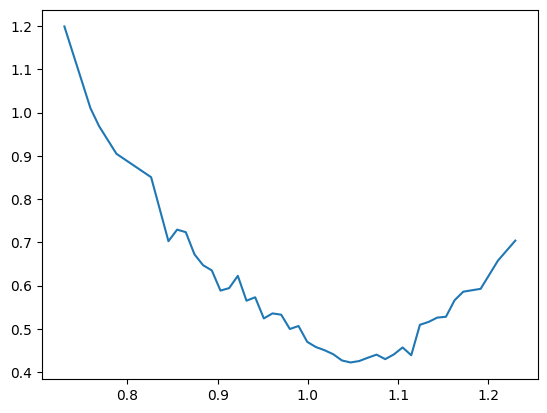

In [39]:
plt.plot(calls["strike"]/S0, IV_list)

In [229]:
import numpy as np
from scipy.stats import norm

def bs_european_call2(S0, K, r, T, sigma):
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    C = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

    return C

## American Options: Longstaff–Schwartz Algorithm

In [62]:
def exercise(X, K):
    return np.maximum(K - X, 0)

In [92]:
X = paths[-1,:]
Y = exercise(X, K)
xplot = np.linspace(np.min(X), np.max(X), N)

p = np.polynomial.Chebyshev.fit(X, Y, 4)

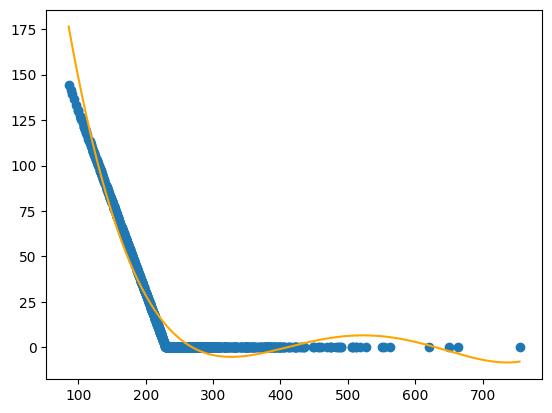

In [93]:
plt.scatter(X, Y)
plt.plot(xplot, p(xplot), c="orange")

In [83]:
dt = 1
#K = 270
deg = 4

Chat_list = [] # Remember to reverse it
tau = np.full(N, T-1, dtype=int)
for t in range(T-2, 0, -1):
    
    X = paths[t,:]
    V = np.exp(-r*(tau-t)*dt)*exercise(paths[tau, np.arange(N)], K)

    itm = X < K
    if itm.sum() > deg+1: # Check that it has enough ITM trajectories to have a good fit
        C_hat = np.polynomial.Chebyshev.fit(X[itm], V[itm], deg) # We want to fit only the ITM part
        tau[itm & (C_hat(X) < K - X)] = t
        Chat_list.append(C_hat)
    else:
        Chat_list.append(None)

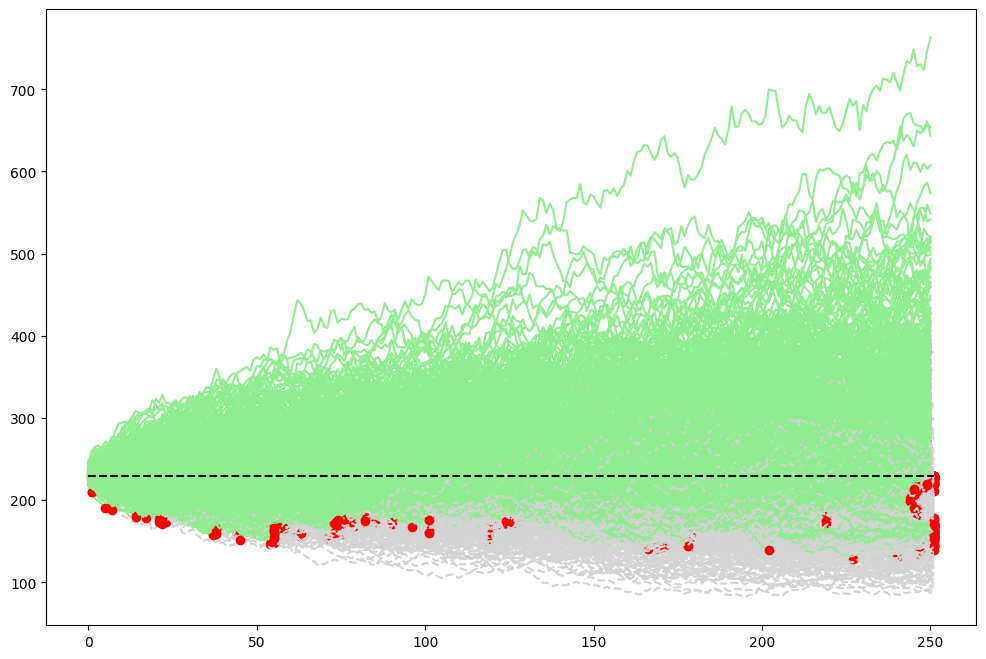

In [84]:
plt.figure(figsize=(12, 8))

for idx in range(paths.shape[1]):
    exercise_time = tau[idx]
    path = paths[:,idx]
    plt.plot(range(exercise_time, T), path[exercise_time:], c="lightgrey", linestyle="--")
    plt.plot(range(exercise_time), path[:exercise_time], c="lightgreen")
    
    if path[exercise_time] < K:
        plt.scatter(exercise_time, path[exercise_time], c="red", zorder=2)

plt.plot(np.arange(T), K*np.ones(T), linestyle="--", c="black")

In [87]:
european = np.exp(-r*T)*np.mean(np.maximum(K - paths[-1,:], 0))
american = 1/N * np.sum(np.exp(-r*(tau+1)*dt)*np.maximum(K - paths[tau, np.arange(N)], 0))

print(european)
print(american)

25.01111454479811
26.480399615407777


In [89]:
#np.exp(-r*T)*np.mean(np.maximum(paths[-1,:] - K, 0))

np.float64(37.53162474791024)

In [86]:
print(american - european)

1.469285070609665
